In [1]:
import yfinance as yf


In [2]:
prices = yf.download(["SMCI", 'QQQ'], start="2020-01-01", end="2026-01-01", auto_adjust=True)

[*********************100%***********************]  2 of 2 completed


<Axes: title={'center': 'SMCI, QQQ, SPY Prices'}, xlabel='Date'>

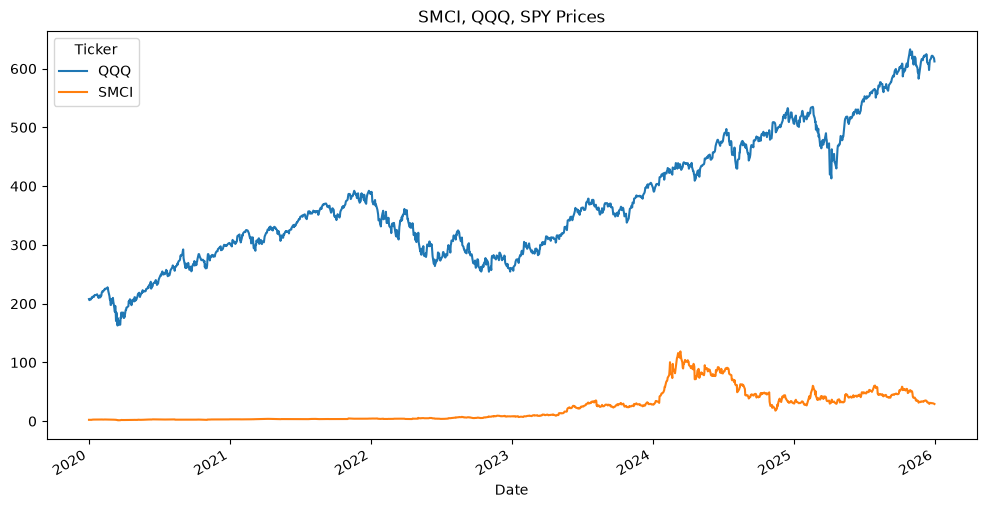

In [3]:
prices['Close'].plot(title="SMCI, QQQ, SPY Prices", figsize=(12, 6))

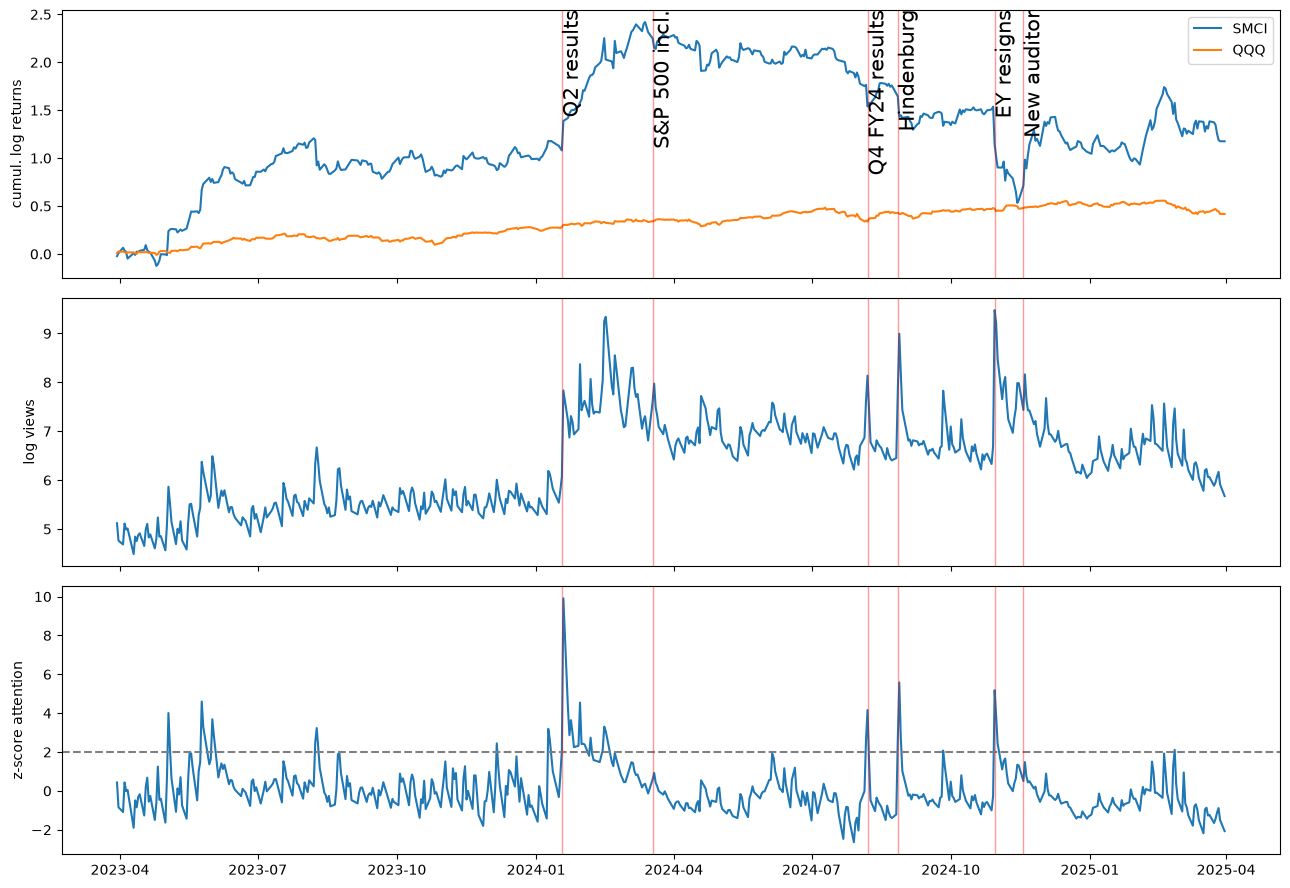

                 mean          std        min           max
r_smci       0.002342     0.065832  -0.395640      0.307016
r_qqq        0.000832     0.011309  -0.039527      0.030132
views      897.873838  1235.911451  88.000000  13040.000000
log_views    6.357689     0.897716   4.488636      9.475854
att_z        0.141161     1.277454  -2.639604      9.910621
gk_SMCI     -3.065986     0.489983  -4.400149     -1.018388
gk_QQQ      -4.700228     0.440365  -5.982204     -2.794122
r_ex         0.001510     0.061768  -0.388053      0.287379
Days with att_z > 2: 38


In [4]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import quote

HEADERS = {"User-Agent": "AAIS-student-project (2markkhomenko@gmail.com)"}  

def wiki_pageviews(title, start="20230101", end="20250331"):

    t = quote(title.replace(" ", "_"), safe="")
    url = ("https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
           f"en.wikipedia/all-access/user/{t}/daily/{start}/{end}")
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    items = r.json()["items"]
    s = pd.Series({pd.to_datetime(i["timestamp"][:8]): i["views"] for i in items}, name=title)
    return s.asfreq("D", fill_value=0)   

views = wiki_pageviews("Supermicro")     

trading_days = prices["Close"]["SMCI"].dropna().index
pos = trading_days.searchsorted(views.index)
ok = pos < len(trading_days)
mapped = trading_days[pos[ok]]


att = views[ok].groupby(mapped).mean().rename("views")


W = 60
log_v = np.log1p(att)
mu = log_v.rolling(W).mean().shift(1) 
sd = log_v.rolling(W).std().shift(1)
att_z = ((log_v - mu) / sd).rename("att_z")


log_hl = np.log(prices["High"] / prices["Low"])
log_co = np.log(prices["Close"] / prices["Open"])

gk_var = 0.5 * (log_hl ** 2) - (2 * np.log(2) - 1) * (log_co ** 2)


log_oc = np.log(prices["Open"] / prices["Close"].shift(1))   

gk_yz_var = log_oc**2 + gk_var




ret = np.log(prices["Close"]).diff()
df = pd.concat({
    "r_smci": ret["SMCI"],
    "r_qqq":  ret["QQQ"],
    "views":  att,
    "log_views": log_v,
    "att_z":  att_z,
    'gk_SMCI':np.log(np.sqrt(gk_yz_var["SMCI"])),
    'gk_QQQ': np.log(np.sqrt(gk_yz_var["QQQ"]))   
}, axis=1).dropna()
df["r_ex"] = df["r_smci"] - df["r_qqq"] 


events = {         
    "Q2 results": "2024-01-18",
    "S&P 500 incl.": "2024-03-18",
    'Q4 FY24 results': "2024-08-07",
    "Hindenburg":    "2024-08-27",
    "EY resigns":    "2024-10-30",
    "New auditor":   "2024-11-18",
}
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
ax[0].plot(df.index, df["r_smci"].cumsum(), label="SMCI")
ax[0].plot(df.index, df["r_qqq"].cumsum(), label="QQQ")
ax[0].set_ylabel("cumul. log returns"); ax[0].legend()
ax[1].plot(df.index, df["log_views"]); ax[1].set_ylabel("log views")
ax[2].plot(df.index, df["att_z"]); ax[2].axhline(2, ls="--", c="grey")
ax[2].set_ylabel("z-score attention")
for a in ax:
    for name, d in events.items():
        a.axvline(pd.Timestamp(d), c="red", alpha=0.4, lw=1)
for name, d in events.items():
    ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1], name, rotation=90, va="top", fontsize=15)
plt.tight_layout()

fig.savefig('task4_attention.png', dpi=120, bbox_inches='tight')



plt.show()

print(df.describe().T[["mean", "std", "min", "max"]])
print("Days with att_z > 2:", (df["att_z"] > 2).sum())

In [5]:
spikes = (df[df["att_z"] > 2]
          .assign(gap=np.log(prices["Open"]["SMCI"] / prices["Close"]["SMCI"].shift(1)))
          [["att_z", "views", "r_ex", "gap"]]
          .sort_values("att_z", ascending=False))
print(spikes.round(3))

            att_z      views   r_ex    gap
Date                                      
2024-01-19  9.911   2524.000  0.287  0.110
2024-08-28  5.579   8051.000 -0.200 -0.120
2024-10-30  5.180  13040.000 -0.388 -0.343
2023-05-25  4.599    586.000  0.186  0.156
2024-01-30  4.544   4317.000  0.041  0.099
2024-01-22  4.302   1362.667  0.029  0.075
2024-08-07  4.161   3417.000 -0.214 -0.147
2023-05-03  4.006    352.000  0.256  0.105
2024-10-31  3.876  10018.000 -0.102 -0.095
2023-06-01  3.684    657.000  0.020  0.012
2024-01-24  3.640   1495.000  0.022  0.030
2024-02-15  3.306  10466.000  0.128  0.071
2023-05-26  3.301    477.000  0.033  0.015
2023-08-09  3.235    787.000 -0.255 -0.156
2024-01-09  3.196    486.000  0.069 -0.006
2024-02-16  3.076  11384.000 -0.214  0.041
2024-01-25  3.008   1337.000  0.010  0.013
2024-01-23  2.864    963.000  0.043 -0.001
2023-06-02  2.858    551.000 -0.048  0.015
2024-02-06  2.741   3190.000  0.029  0.014
2024-08-29  2.730   3580.000  0.013 -0.017
2024-01-10 

### STRETCH PART

In [6]:
logO, logC = np.log(prices["Open"]), np.log(prices["Close"])
intra = logC - logO
gap   = logO - logC.shift(1)

In [7]:
logC

Ticker,QQQ,SMCI
Date,,
2020-01-02,5.336924,0.859932
2020-01-03,5.327722,0.851859
2020-01-06,5.334144,0.844580
2020-01-07,5.334005,0.837247
2020-01-08,5.341493,0.835948
...,...,...
2025-12-24,6.432638,3.419365
2025-12-26,6.432574,3.422306
2025-12-29,6.427722,3.403860


In [8]:
df["intra_ex"] = (intra["SMCI"] - intra["QQQ"]).reindex(df.index)
df["gap_ex"]   = (gap["SMCI"]   - gap["QQQ"]).reindex(df.index)
df["vol_ex"]   = df["gk_SMCI"] - df["gk_QQQ"]
df["abs_r_ex"] = df["r_ex"].abs()


df["phase"] = "calm"
df.loc["2024-01-01":"2024-03-31", "phase"] = "hype"
df.loc["2024-08-01":"2024-12-31", "phase"] = "scandal"


df["r_ex_next"]     = df["r_ex"].shift(-1)
df["gap_ex_next"]   = df["gap_ex"].shift(-1)
df["intra_ex_next"] = df["intra_ex"].shift(-1)

In [9]:
df

,r_smci,r_qqq,views,log_views,att_z,gk_SMCI,gk_QQQ,r_ex,intra_ex,gap_ex,vol_ex,abs_r_ex,phase,r_ex_next,gap_ex_next,intra_ex_next
Date,,,,,,,,,,,,,,,,
2023-03-30,-0.022107,0.009421,166.000000,5.117994,0.433604,-3.302015,-4.489943,-0.031528,-0.039185,0.007658,1.187928,0.031528,calm,0.014096,0.001398,0.012698
2023-03-31,0.030590,0.016494,116.000000,4.762174,-0.841277,-3.691040,-4.881405,0.014096,0.012698,0.001398,1.190365,0.014096,calm,0.058726,0.006941,0.051785
2023-04-03,0.056293,-0.002433,107.333333,4.685213,-1.085188,-3.901281,-4.700515,0.058726,0.051785,0.006941,0.799235,0.058726,calm,-0.025969,0.008483,-0.034451
2023-04-04,-0.029348,-0.003379,165.000000,5.111988,0.434577,-3.030927,-4.830176,-0.025969,-0.034451,0.008483,1.799249,0.025969,calm,-0.003229,-0.007517,0.004288
2023-04-05,-0.013150,-0.009921,146.000000,4.990433,-0.007650,-3.572386,-4.534236,-0.003229,0.004288,-0.007517,0.961850,0.003229,calm,-0.077082,-0.073508,-0.003574
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-25,-0.026228,0.005690,385.000000,5.955837,-1.439373,-2.915033,-5.505044,-0.031918,-0.027070,-0.004848,2.590010,0.031918,calm,-0.074182,-0.006048,-0.068134
2025-03-26,-0.092754,-0.018572,435.000000,6.077642,-1.114522,-2.861515,-4.480060,-0.074182,-0.068134,-0.006048,1.618545,0.074182,calm,-0.058968,-0.013629,-0.045339
2025-03-27,-0.064683,-0.005714,477.000000,6.169611,-0.883036,-3.353145,-4.598696,-0.058968,-0.045339,-0.013629,1.245551,0.058968,calm,0.013343,0.004917,0.008427


In [10]:
import statsmodels.formula.api as smf

H = [1, 3, 5, 10]
for k in H:
    fwd = logC.shift(-k) - logO.shift(-1)
    df[f"fwd_{k}"] = (fwd["SMCI"] - fwd["QQQ"]).reindex(df.index)

df["extreme"] = (df["att_z"] > 2).astype(int)

def ols(formula, lags=5):
    return smf.ols(formula, data=df).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

def show(m, terms):
    print(m.model.formula, f"| n={int(m.nobs)}, R2={m.rsquared:.3f}")
    for t in terms:
        print(f"   {t:<28} b={m.params[t]: .4f}   t={m.tvalues[t]: .2f}")

In [11]:
def show(m, terms):
    print(m.model.formula, f"| n={int(m.nobs)}, R2={m.rsquared:.3f}")
    for t in terms:
        print(f"   {t:<28} b={m.params[t]: .4f}   t={m.tvalues[t]: .2f}")


print("=== A. Contemporaneous ===")
show(ols("r_ex ~ att_z"),     ["att_z"])
show(ols("abs_r_ex ~ att_z"), ["att_z"])
show(ols("vol_ex ~ att_z"),   ["att_z"])
mA = ols("r_ex ~ C(phase) + att_z:C(phase)")
show(mA, [p for p in mA.params.index if "att_z" in p])

=== A. Contemporaneous ===
r_ex ~ att_z | n=502, R2=0.002
   att_z                        b= 0.0023   t= 0.42
abs_r_ex ~ att_z | n=502, R2=0.187
   att_z                        b= 0.0159   t= 5.71
vol_ex ~ att_z | n=502, R2=0.129
   att_z                        b= 0.1620   t= 6.36
r_ex ~ C(phase) + att_z:C(phase) | n=502, R2=0.112
   att_z:C(phase)[calm]         b= 0.0061   t= 1.26
   att_z:C(phase)[hype]         b= 0.0171   t= 2.76
   att_z:C(phase)[scandal]      b=-0.0254   t=-3.05


In [12]:
print("\n=== B. Predictive (att_z_t -> t+1) ===")
show(ols("r_ex_next ~ att_z + r_ex"),     ["att_z", "r_ex"])
show(ols("gap_ex_next ~ att_z + r_ex"),   ["att_z", "r_ex"])   
show(ols("intra_ex_next ~ att_z + r_ex"), ["att_z", "r_ex"])


=== B. Predictive (att_z_t -> t+1) ===
r_ex_next ~ att_z + r_ex | n=501, R2=0.000
   att_z                        b= 0.0005   t= 0.21
   r_ex                         b= 0.0077   t= 0.14
gap_ex_next ~ att_z + r_ex | n=501, R2=0.015
   att_z                        b= 0.0002   t= 0.13
   r_ex                         b= 0.0786   t= 2.46
intra_ex_next ~ att_z + r_ex | n=501, R2=0.010
   att_z                        b= 0.0003   t= 0.19
   r_ex                         b=-0.0709   t=-1.68


In [13]:
print("\n=== C. Reversal after extreme attention ===")
print("extreme days:", df["extreme"].sum())
for k in H:
    show(ols(f"fwd_{k} ~ r_ex + r_ex:extreme", lags=max(k, 5)),
         ["r_ex", "r_ex:extreme"])


=== C. Reversal after extreme attention ===
extreme days: 38
fwd_1 ~ r_ex + r_ex:extreme | n=502, R2=0.011
   r_ex                         b=-0.0516   t=-0.91
   r_ex:extreme                 b=-0.0565   t=-0.65
fwd_3 ~ r_ex + r_ex:extreme | n=502, R2=0.001
   r_ex                         b=-0.0262   t=-0.29
   r_ex:extreme                 b=-0.0598   t=-0.27
fwd_5 ~ r_ex + r_ex:extreme | n=502, R2=0.002
   r_ex                         b=-0.0309   t=-0.24
   r_ex:extreme                 b= 0.1840   t= 0.72
fwd_10 ~ r_ex + r_ex:extreme | n=502, R2=0.011
   r_ex                         b=-0.1797   t=-1.10
   r_ex:extreme                 b= 0.7279   t= 1.71


In [14]:
ext = df[df["extreme"] == 1].copy()
ext["move"] = np.where(ext["r_ex"] > 0, "up", "down")
print(ext.groupby("move")[[f"fwd_{k}" for k in H]].agg(["mean", "count"]).round(4))

       fwd_1         fwd_3         fwd_5        fwd_10      
        mean count    mean count    mean count    mean count
move                                                        
down  0.0170    15  0.0185    15  0.0046    15  0.0298    15
up   -0.0156    23  0.0021    23  0.0509    23  0.1931    23


In [16]:
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side

header_fill = PatternFill('solid', start_color='F4B183')
first_col_fill = PatternFill('solid', start_color='FCE4D6')
side = Side(style='thin', color='000000')
border = Border(left=side, right=side, top=side, bottom=side)

def write_block(xw, ws, df, startrow, title, fmt):
    df.to_excel(xw, sheet_name='Report', startrow=startrow + 1)
    ws.cell(startrow + 1, 1, title).font = Font(name='Arial', size=12, bold=True)
    head = startrow + 2
    for row in ws.iter_rows(min_row=head, max_row=head + len(df), max_col=df.shape[1] + 1):
        for c in row:
            c.border = border
            c.font = Font(name='Arial', size=10)
            if c.row == head:
                c.fill, c.font = header_fill, Font(name='Arial', size=10, bold=True)
                c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
            elif c.column == 1:
                c.fill = first_col_fill
            else:
                c.alignment = Alignment(horizontal='right')
                if isinstance(c.value, (int, float)):
                    c.number_format = fmt(str(ws.cell(c.row, 1).value), str(ws.cell(head, c.column).value))
    return head + len(df) + 2

desc = df[['r_smci', 'r_qqq', 'r_ex', 'views', 'log_views', 'att_z', 'gk_SMCI', 'gk_QQQ']] \
         .describe().T[['mean', 'std', 'min', 'max']]
desc.columns = ['Mean', 'Std', 'Min', 'Max']
desc.index = ['SMCI log return', 'QQQ log return', 'SMCI excess return (vs QQQ)',
              'Wikipedia views', 'Log views', 'Abnormal attention (z-score)',
              'SMCI log volatility (GK + gap)', 'QQQ log volatility (GK + gap)']
desc.index.name = 'Variable'

def one(m, term):
    return [m.params[term], m.tvalues[term], m.rsquared, int(m.nobs)]

mA = ols('r_ex ~ C(phase) + att_z:C(phase)')
contemp = pd.DataFrame([
    one(ols('r_ex ~ att_z'), 'att_z'),
    one(ols('abs_r_ex ~ att_z'), 'att_z'),
    one(ols('vol_ex ~ att_z'), 'att_z'),
    one(mA, 'att_z:C(phase)[calm]'),
    one(mA, 'att_z:C(phase)[hype]'),
    one(mA, 'att_z:C(phase)[scandal]'),
], index=['Excess return', 'Absolute excess return', 'Excess log volatility',
          'Excess return: calm phase', 'Excess return: hype phase', 'Excess return: scandal phase'],
   columns=['Attention coef', 'Attention t-stat', 'R²', 'N'])
contemp.index.name = 'Dependent variable (day t)'

def two(m):
    return [m.params['att_z'], m.tvalues['att_z'], m.params['r_ex'], m.tvalues['r_ex'], m.rsquared, int(m.nobs)]

pred = pd.DataFrame([
    two(ols('r_ex_next ~ att_z + r_ex')),
    two(ols('gap_ex_next ~ att_z + r_ex')),
    two(ols('intra_ex_next ~ att_z + r_ex')),
], index=['Next-day return (close to close)', 'Next-day overnight gap (not tradable)',
          'Next-day intraday return (tradable)'],
   columns=['Attention coef', 'Attention t-stat', 'Same-day return coef', 'Same-day return t-stat', 'R²', 'N'])
pred.index.name = 'Dependent variable (day t+1)'

rows = []
for k in H:
    m = ols(f'fwd_{k} ~ r_ex + r_ex:extreme', lags=max(k, 5))
    rows.append([m.params['r_ex'], m.tvalues['r_ex'], m.params['r_ex:extreme'],
                 m.tvalues['r_ex:extreme'], m.rsquared, int(m.nobs)])
rev = pd.DataFrame(rows, index=[f'{k} day' + ('s' if k > 1 else '') for k in H],
                   columns=['Same-day return coef', 'Same-day return t-stat',
                            'Return × extreme coef', 'Return × extreme t-stat', 'R²', 'N'])
rev.index.name = 'Horizon (open t+1 to close t+k)'

follow = ext.groupby('move')[[f'fwd_{k}' for k in H]].mean()
follow.columns = [f'{k}-day excess return' for k in H]
follow['N'] = ext.groupby('move').size()
follow = follow.rename(index={'down': 'Extreme attention, down day', 'up': 'Extreme attention, up day'})
follow.index.name = 'Day type'

def fmt(label, col):
    if col == 'N':
        return '0'
    if col == 'R²':
        return '0.000'
    if 't-stat' in col:
        return '0.00'
    if 'excess return' in col:
        return '0.00%'
    if label == 'Wikipedia views':
        return '#,##0'
    return '0.0000'

with pd.ExcelWriter('task4_results.xlsx', engine='openpyxl') as xw:
    pd.DataFrame().to_excel(xw, sheet_name='Report')
    ws = xw.sheets['Report']
    ws['A1'] = 'SMCI 2024: Wikipedia attention, returns and volatility'
    ws['A1'].font = Font(name='Arial', size=14, bold=True)

    r = 2
    r = write_block(xw, ws, desc, r, 'Descriptive statistics (daily)', fmt)
    r = write_block(xw, ws, contemp, r, 'A. Contemporaneous relationship', fmt)
    r = write_block(xw, ws, pred, r, 'B. Predictive content', fmt)
    r = write_block(xw, ws, rev, r, 'C. Reversal after extreme attention (z > 2)', fmt)
    r = write_block(xw, ws, follow, r, 'C. Excess return after extreme-attention days', fmt)

    ws.column_dimensions['A'].width = 40
    for col in 'BCDEFG':
        ws.column_dimensions[col].width = 16